# 2. Analysis: mRNA per cell and size scaling

**Step 5 of the workflow** (see the README). Input: `outputs/<plate>/aggregated/` from step 2, counted with the
thresholds checked in notebook 1. Runs on a laptop. Tables go to `results/<plate>/`, figures to
`outputs/<plate>/figures/analysis/`.

Conventions:
- **Cells**: QC-passing cells only (not touching the field border, >= 0.4 pL, with a nucleus >= 0.1 pL).
  Cells without spots are kept (a count of 0 is data).
- **Compartments**: nucleus, and cytoplasm (with the 1 µm perinuclear shell folded in); the whole cell is their sum.
- **Uncertainty**: 95% intervals from resampling whole fields of view, the unit closest to a replicate here,
  not single cells.

Sections: 1 cells per well; 2 mRNA per cell for every probe, next to the negative controls; 3 size scaling of the
main readout; 4 expression noise against cell size.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from smfish import style as S
from smfish.analysis import bootstrap_over_fovs, fano_window_check, noise_by_bins, per_cell_counts, rolling_moments, scaling_slope
from smfish.figures import fig_compartment_own_volume, fig_compartment_scaling, fig_total_scaling, label_panels, save
from smfish.layout import load_layout
from smfish.notebook import setup

PLATE = os.environ.get("SMFISH_PLATE", "250806")
plate = setup(PLATE, "analysis")
N_BOOT = int(os.environ.get("SMFISH_N_BOOT", "200"))   # field resamples for the noise ribbons and tercile CIs
cells = pd.read_parquet(plate.agg / "cells.parquet")
long = pd.read_parquet(plate.agg / "cell_counts_long.parquet")
layout = load_layout(plate.cfg)
CONDITIONS = list(plate.cfg["conditions"])

## 1. Cells per well
QC cells and their volumes. A well whose cells differ much in size from the others would need a closer look
before its counts are compared.

In [2]:
qc = cells[cells["qc_pass"]]
per_well = (cells.groupby(["well", "condition"])
            .agg(fields=("fov_id", "nunique"), cells=("cell_id", "size"), qc_cells=("qc_pass", "sum"))
            .join(qc.groupby("well").agg(cell_pL=("cell_volume_um3", "median"), nucleus_pL=("nucleus_volume_um3", "median"))
                  / 1000))
per_well.to_csv(plate.results / "cells_per_well.csv")
display(per_well.round(2))

,,fields,cells,qc_cells,cell_pL,nucleus_pL
well,condition,,,,,
1,POLR2A-Streaming,25,662,457,1.48,0.97
2,POLR2A-Streaming,25,729,386,2.71,1.03
3,OsTIRF47G,25,532,286,2.19,0.83
4,POLR2A-Streaming,25,565,267,2.40,0.92
5,OsTIRF47G,25,951,529,2.12,0.83
6,POLR2A-Streaming,25,892,477,2.39,0.91
7,POLR2A-Streaming,25,693,371,2.31,0.90
8,POLR2A-Streaming,25,724,371,2.19,0.85
9,OsTIRF47G,25,930,526,2.03,0.79


## 2. mRNA per cell, for every probe, next to the negative controls
Mean spots per QC cell (95% interval over fields) in each well and channel. Transcription-site probes (introns)
count nuclear sites, not mRNAs. Negative controls (purple: mrcB, and NeoR / TetO in the parental line, where
their targets are absent) show the false-positive floor at the calibrated thresholds: about 1 spot per cell, or
0.1 per nucleus for TetO. A few knock-in wells show almost no POLR2A evens staining (250806: W2, W17; 250929: W12):
a failed hybridisation, not biology (their odds probes and the other evens wells are normal; notebook 1, section 4).

,channel,probe,role,negative_control,well,condition,compartment,estimate,ci_low,ci_high,n_fov
96,Atto565,mrcB,neg_control,True,1,POLR2A-Streaming,cell,1.04,0.92,1.16,25
60,Atto565,POLR2A odds exon,exon,False,2,POLR2A-Streaming,cell,53.73,51.25,56.18,25
63,Atto565,POLR2A odds exon,exon,False,3,OsTIRF47G,cell,102.72,98.70,106.96,25
42,Atto565,POLR2A intron,intron,False,4,POLR2A-Streaming,cell,1.35,1.20,1.51,25
45,Atto565,POLR2A intron,intron,False,5,OsTIRF47G,cell,3.59,3.35,3.85,25
3,Atto565,GAPDH exon,exon,False,6,POLR2A-Streaming,cell,1036.94,997.73,1081.28,25
78,Atto565,POLR2B odds exon,exon,False,7,POLR2A-Streaming,cell,69.37,66.57,72.67,25
66,Atto565,POLR2A odds exon,exon,False,8,POLR2A-Streaming,cell,53.76,50.87,57.20,25
69,Atto565,POLR2A odds exon,exon,False,9,OsTIRF47G,cell,93.38,88.47,99.11,25
48,Atto565,POLR2A intron,intron,False,10,POLR2A-Streaming,cell,3.76,3.42,4.12,25


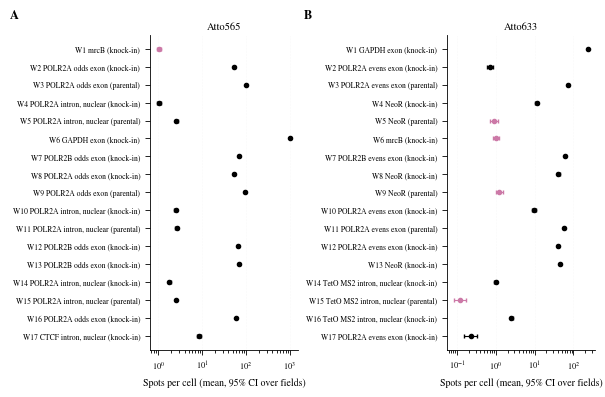

In [3]:
imaged = layout[layout["well"].isin(cells["well"].unique())]   # wells in the layout that were imaged
probes = imaged[["well", "condition", "channel", "probe", "role", "expected_absent"]]
rows = []
for (probe, channel), d in probes.groupby(["probe", "channel"]):
    counts = per_cell_counts(long, cells, probe, channel, compartments=("cell", "nucleus", "cytoplasm"))
    counts = counts.merge(d[["well"]], on="well")
    est = bootstrap_over_fovs(counts, "n_spots", ["well", "condition", "compartment"], n_boot=1000)
    rows.append(est.assign(probe=probe, channel=channel))
mrna = (pd.concat(rows, ignore_index=True)
        .merge(probes[["well", "channel", "role", "expected_absent"]], on=["well", "channel"]))
mrna["negative_control"] = (mrna["role"] == "neg_control") | mrna["expected_absent"]
mrna = mrna[["channel", "probe", "role", "negative_control", "well", "condition", "compartment", "estimate",
             "ci_low", "ci_high", "n_fov"]].sort_values(["channel", "well", "compartment"])
mrna.to_csv(plate.results / "spots_per_cell.csv", index=False)
display(mrna[mrna["compartment"] == "cell"].round(2))

with S.use("publication"):
    # whole cell for mRNA probes, nucleus for transcription sites
    whole = mrna[mrna["compartment"] == np.where(mrna["role"] == "intron", "nucleus", "cell")]
    fig, axes = plt.subplots(1, 2, figsize=(S.TEXT_WIDTH_MM * S.MM, 95 * S.MM), layout="constrained")
    for ax, (channel, d) in zip(axes, whole.groupby("channel")):
        d = d.sort_values("well", ascending=False).reset_index(drop=True)
        for i, r in d.iterrows():
            colour = S.PURPLE if r["negative_control"] else S.BLACK
            ax.errorbar(r["estimate"], i, xerr=[[r["estimate"] - r["ci_low"]], [r["ci_high"] - r["estimate"]]],
                        fmt="o", color=colour, ms=3, capsize=1.5, lw=0.8)
        line = {c: ("knock-in" if i == 0 else "parental") for i, c in enumerate(CONDITIONS)}
        ax.set_yticks(range(len(d)), [f"W{r.well} {r.probe}{', nuclear' if r.role == 'intron' else ''} "
                                      f"({line.get(r.condition, r.condition)})" for r in d.itertuples()], fontsize=5.5)
        ax.set(xscale="log", xlabel="Spots per cell (mean, 95% CI over fields)", title=channel)
        ax.grid(axis="y", visible=False)
    label_panels(fig, [(axes[0], "A"), (axes[1], "B")])
    save(fig, "spots_per_cell", plate.figures)
    plt.show()

## 3. Size scaling of the main readout
POLR2A mRNA (odds exon probe set, Atto565) in the knock-in and the parental line, against cell volume. A log-log
slope of 1 means mRNA number rises in proportion to cell volume (constant concentration). Fig A: whole cell, with
the Fano factor (variance / mean) in sliding windows of cell volume underneath, against the Poisson value of 1.
Fig B: nucleus and cytoplasm against cell volume, with the excess CV² ((variance - mean) / mean²) row.
Fig C: each compartment against its *own* volume, and how each compartment's volume scales with cell volume
(slope against cell volume ≈ slope against own volume x own volume's slope against cell volume).

The Fano factor is only read as expression noise if it is stable to the window size (`fano_window_*` columns):
if it climbs with the window, it is measuring the spread of cell sizes inside the window instead.

In [4]:
PROBE, CHANNEL = "POLR2A odds exon", "Atto565"
counts = per_cell_counts(long, cells, PROBE, CHANNEL, compartments=("cell", "nucleus", "cytoplasm"))
print(counts[counts["compartment"] == "cell"].groupby(["condition", "well"]).size().rename("qc_cells").to_string())

slopes = scaling_slope(counts, "cell_volume_pL", "n_spots", ["condition", "compartment"])
fano_rows = []
for (cond, comp), d in counts.groupby(["condition", "compartment"]):
    # variance within wells only (as in the figures): differences between wells are not cell-to-cell noise
    r = rolling_moments(d, "cell_volume_pL", "n_spots", within="well")
    chk = fano_window_check(d, "cell_volume_pL", "n_spots")
    fano_rows.append({"condition": cond, "compartment": comp, "mean_count": d["n_spots"].mean(),
                      "median_fano": r["fano"].median(),
                      **{f"fano_window_{w:g}": f for w, f in zip(chk["window"], chk["median_fano"])}})
summary = slopes.merge(pd.DataFrame(fano_rows), on=["condition", "compartment"])

own = pd.concat([scaling_slope(counts[counts["compartment"] == comp], f"{comp}_volume_pL", "n_spots",
                               ["condition", "compartment"]) for comp in ("nucleus", "cytoplasm")])
summary = summary.merge(own[["condition", "compartment", "slope", "ci_low", "ci_high"]],
                        on=["condition", "compartment"], how="left", suffixes=("", "_own_volume"))
nuclei = counts[counts["compartment"] == "nucleus"]   # one row per cell
volume_slopes = pd.concat([scaling_slope(nuclei, "cell_volume_pL", f"{comp}_volume_pL", ["condition"])
                           .assign(compartment=comp) for comp in ("nucleus", "cytoplasm")])
summary = summary.merge(volume_slopes[["condition", "compartment", "slope", "ci_low", "ci_high"]],
                        on=["condition", "compartment"], how="left", suffixes=("", "_volume_vs_cell"))
summary.to_csv(plate.results / "scaling_summary.csv", index=False)
display(summary.round(3))

condition         well
OsTIRF47G         3       286
                  9       526
POLR2A-Streaming  2       386
                  8       371
                  16      547


,condition,compartment,slope,ci_low,ci_high,n_cells,n_zero,n_fov,mean_count,median_fano,fano_window_0.05,fano_window_0.1,fano_window_0.2,slope_own_volume,ci_low_own_volume,ci_high_own_volume,slope_volume_vs_cell,ci_low_volume_vs_cell,ci_high_volume_vs_cell
0,OsTIRF47G,cell,1.224,1.075,1.401,812,0,50,96.670,7.374,7.499,7.379,7.979,NaN,NaN,NaN,NaN,NaN,NaN
1,OsTIRF47G,cytoplasm,1.360,1.192,1.548,812,0,50,78.398,7.474,7.589,7.402,8.453,1.278,1.171,1.406,1.134,1.092,1.180
2,OsTIRF47G,nucleus,0.752,0.612,0.892,812,6,50,18.272,2.194,2.179,2.203,2.187,0.816,0.677,0.953,0.851,0.792,0.909
3,POLR2A-Streaming,cell,1.167,1.051,1.278,1304,1,75,56.688,5.421,5.966,6.008,6.265,NaN,NaN,NaN,NaN,NaN,NaN
4,POLR2A-Streaming,cytoplasm,1.204,1.090,1.328,1304,3,75,46.161,5.535,5.919,5.889,6.132,1.160,1.055,1.279,1.103,1.076,1.130
5,POLR2A-Streaming,nucleus,0.791,0.672,0.907,1304,27,75,10.527,2.104,2.433,2.446,2.571,0.918,0.808,1.024,0.894,0.857,0.932


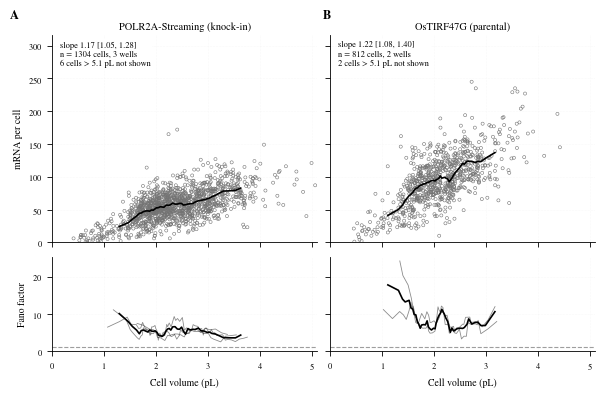

In [5]:
with S.use("publication"):
    fig_a = fig_total_scaling(counts[counts["compartment"] == "cell"], slopes)
    save(fig_a, "total_scaling", plate.figures)
    plt.show()

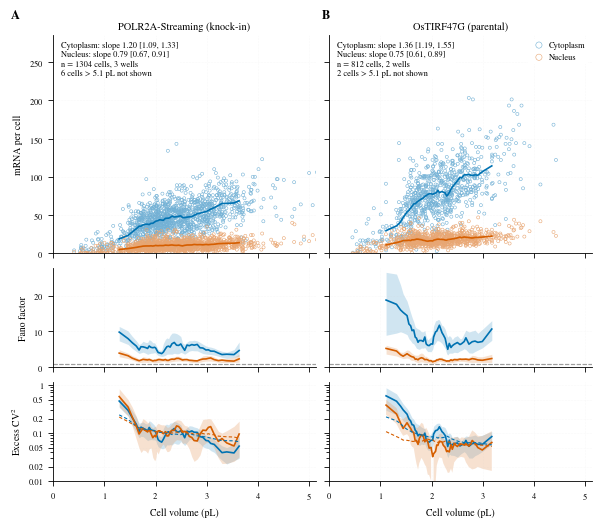

In [6]:
with S.use("publication"):
    fig_b = fig_compartment_scaling(counts[counts["compartment"] != "cell"], slopes, n_boot=N_BOOT)
    save(fig_b, "compartment_scaling", plate.figures)
    plt.show()

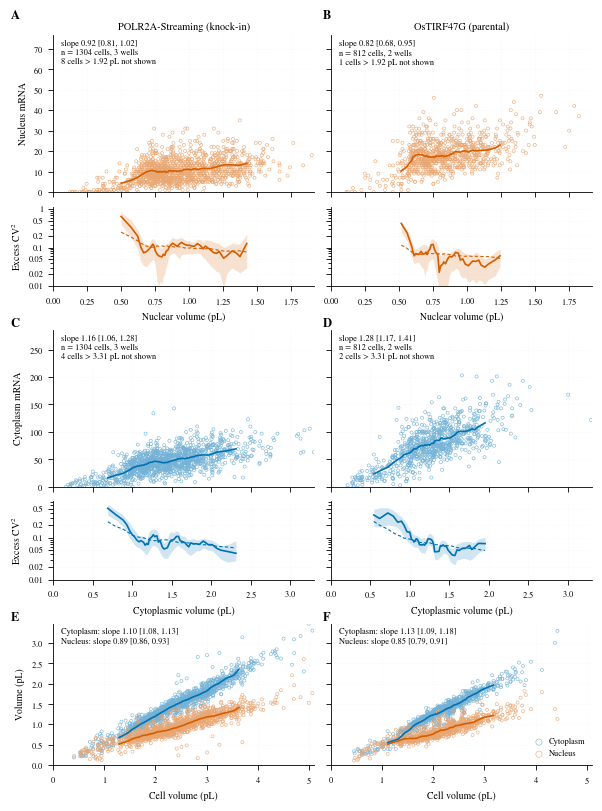

In [7]:
with S.use("publication"):
    fig_c = fig_compartment_own_volume(counts[counts["compartment"] != "cell"], own, volume_slopes=volume_slopes,
                                       n_boot=N_BOOT)
    save(fig_c, "compartment_own_volume", plate.figures)
    plt.show()

## 4. Expression noise against cell size
Cells split into volume terciles per cell line. Per tercile and compartment: the mean, the Fano factor and the
excess CV² (medians of the sliding windows inside the tercile, so the size spread within a tercile does not
inflate them; 95% intervals from resampling fields). Nucleus and cytoplasm differ in mean, so their Fano factors
alone do not say which is noisier; excess CV² does. `excess_cv2_const_fano` is what the excess CV² would be if the
Fano factor stayed at its population value: a measured value above it is noise that does not fall as the mean
rises. Spots (a transcription site = 1) and intensity-based transcript equivalents (`n_rna`) side by side.

In [8]:
tercile_rows = []
for cond, dcond in counts.groupby("condition"):
    edges = dcond.loc[dcond["compartment"] == "cell", "cell_volume_pL"].quantile([0, 1 / 3, 2 / 3, 1]).to_numpy()
    for comp, d in dcond.groupby("compartment"):
        for y in ("n_spots", "n_rna"):
            t = noise_by_bins(d, "cell_volume_pL", y, edges, n_boot=N_BOOT if y == "n_spots" else 0)
            tercile_rows.append(t.rename(columns={"bin": "tercile", "lo": "vol_lo_pL", "hi": "vol_hi_pL"})
                                .assign(condition=cond, compartment=comp, count=y))
terciles = pd.concat(tercile_rows, ignore_index=True)
first = ["condition", "compartment", "count", "tercile", "vol_lo_pL", "vol_hi_pL", "n_cells", "mean", "fano",
         "fano_lo", "fano_hi", "excess_cv2", "excess_cv2_lo", "excess_cv2_hi", "excess_cv2_const_fano"]
terciles = terciles[first + [c for c in terciles.columns if c not in first]]
terciles.to_csv(plate.results / "noise_by_tercile.csv", index=False)
display(terciles[terciles["count"] == "n_spots"][first].round(3))

,condition,compartment,count,tercile,vol_lo_pL,vol_hi_pL,n_cells,mean,fano,fano_lo,fano_hi,excess_cv2,excess_cv2_lo,excess_cv2_hi,excess_cv2_const_fano
0,OsTIRF47G,cell,n_spots,1,0.453,1.848,271,68.620,9.831,7.038,12.566,0.111,0.075,0.152,0.080
1,OsTIRF47G,cell,n_spots,2,1.848,2.355,270,95.904,7.389,5.870,8.408,0.067,0.052,0.080,0.067
2,OsTIRF47G,cell,n_spots,3,2.355,8.235,271,125.483,6.867,5.028,8.264,0.047,0.036,0.059,0.052
6,OsTIRF47G,cytoplasm,n_spots,1,0.453,1.848,271,52.782,10.421,7.761,13.423,0.149,0.110,0.208,0.105
7,OsTIRF47G,cytoplasm,n_spots,2,1.848,2.355,270,78.493,8.057,6.224,9.018,0.089,0.066,0.105,0.083
8,OsTIRF47G,cytoplasm,n_spots,3,2.355,8.235,271,103.919,6.928,5.456,8.196,0.059,0.043,0.072,0.064
12,OsTIRF47G,nucleus,n_spots,1,0.453,1.848,271,15.838,2.926,2.222,3.642,0.108,0.069,0.156,0.069
13,OsTIRF47G,nucleus,n_spots,2,1.848,2.355,270,17.411,1.884,1.524,2.319,0.050,0.030,0.073,0.068
14,OsTIRF47G,nucleus,n_spots,3,2.355,8.235,271,21.565,2.176,1.656,2.547,0.058,0.034,0.073,0.057
18,POLR2A-Streaming,cell,n_spots,1,0.411,2.032,435,40.782,5.442,4.367,6.484,0.091,0.070,0.123,0.093
